## 1 - imports and setup

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd

sys.path.insert(0, os.path.abspath('..'))

import config
from src.experiment import load_experiment_log, log_run
from src.tuning import tune_catboost, tune_lightgbm, tune_xgboost

optuna.logging.set_verbosity(optuna.logging.WARNING)

# set n_trials
n_trials = 50

## 2 - load data

In [2]:
X_train = pd.read_parquet(config.RESULTS_PATH / "X_train_selected.parquet")
X_val   = pd.read_parquet(config.RESULTS_PATH / "X_val_selected.parquet")
y_train = pd.read_parquet(config.RESULTS_PATH / "y_train.parquet").squeeze()
y_val   = pd.read_parquet(config.RESULTS_PATH / "y_val.parquet").squeeze()

print(f"X_train: {X_train.shape}")
print(f"X_val:   {X_val.shape}")
print(f"y_train fraud rate: {y_train.mean():.4f}")

X_train: (413378, 115)
X_val:   (88581, 115)
y_train fraud rate: 0.0352


## 3 - tune catboost

In [3]:
cat_best_params, cat_study = tune_catboost(
    X_train, y_train, X_val, y_val, n_trials=n_trials
)
cat_best_auc = cat_study.best_value

print("best params:", cat_best_params)
print(f"best val AUC: {cat_best_auc:.5f}")

  0%|          | 0/50 [00:00<?, ?it/s]

best params: {'iterations': 1300, 'learning_rate': 0.08822094140606979, 'depth': 8, 'l2_leaf_reg': 7.857800899303629, 'bagging_temperature': 0.17920044268272478}
best val AUC: 0.92330


## 4 - tune xgboost

In [4]:
xgb_best_params, xgb_study = tune_xgboost(
    X_train, y_train, X_val, y_val, n_trials=n_trials
)
xgb_best_auc = xgb_study.best_value

print("best params:", xgb_best_params)
print(f"best val AUC: {xgb_best_auc:.5f}")

  0%|          | 0/50 [00:00<?, ?it/s]

best params: {'n_estimators': 700, 'learning_rate': 0.0331739565924497, 'max_depth': 8, 'subsample': 0.641701337349787, 'colsample_bytree': 0.9276269504938003, 'min_child_weight': 10}
best val AUC: 0.92525


## 5 - tune lightgbm

In [5]:
lgb_best_params, lgb_study = tune_lightgbm(
    X_train, y_train, X_val, y_val, n_trials=n_trials
)
lgb_best_auc = lgb_study.best_value

print("best params:", lgb_best_params)
print(f"best val AUC: {lgb_best_auc:.5f}")

  0%|          | 0/50 [00:00<?, ?it/s]

best params: {'num_boost_round': 1500, 'learning_rate': 0.03967957572302009, 'max_depth': 8, 'num_leaves': 27, 'min_child_samples': 75, 'subsample': 0.9560642338982602, 'colsample_bytree': 0.856212053346252}
best val AUC: 0.91585


## 6 - results summary

In [6]:
# best params side by side
summary = pd.DataFrame({
    "catboost":  pd.Series(cat_best_params),
    "xgboost":   pd.Series(xgb_best_params),
    "lightgbm":  pd.Series(lgb_best_params),
})
display(summary)

# best AUC per model
auc_summary = pd.DataFrame({
    "model":        ["catboost", "xgboost", "lightgbm"],
    "best_val_auc": [cat_best_auc, xgb_best_auc, lgb_best_auc],
}).sort_values("best_val_auc", ascending=False).reset_index(drop=True)
display(auc_summary)

,catboost,xgboost,lightgbm
bagging_temperature,0.179200,NaN,NaN
colsample_bytree,NaN,0.927627,0.856212
depth,8.000000,NaN,NaN
iterations,1300.000000,NaN,NaN
l2_leaf_reg,7.857801,NaN,NaN
learning_rate,0.088221,0.033174,0.039680
max_depth,NaN,8.000000,8.000000
min_child_samples,NaN,NaN,75.000000
min_child_weight,NaN,10.000000,NaN
n_estimators,NaN,700.000000,NaN


,model,best_val_auc
0,xgboost,0.925253
1,catboost,0.923302
2,lightgbm,0.915846


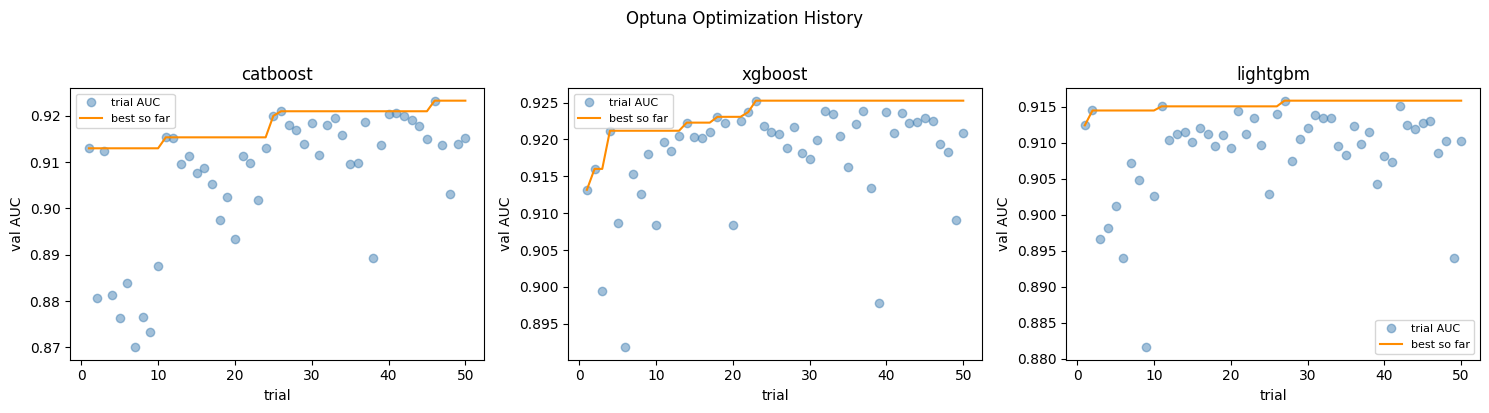

In [7]:
# optimization history -- trial number vs best AUC so far
studies = [
    ("catboost",  cat_study),
    ("xgboost",   xgb_study),
    ("lightgbm",  lgb_study),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=False)

for ax, (name, study) in zip(axes, studies):
    trial_values = [t.value for t in study.trials if t.value is not None]
    best_so_far  = np.maximum.accumulate(trial_values)
    trial_nums   = np.arange(1, len(trial_values) + 1)
    ax.plot(trial_nums, trial_values, 'o', alpha=0.5, color='steelblue', label='trial AUC')
    ax.plot(trial_nums, best_so_far, '-', color='darkorange', label='best so far')
    ax.set_title(name)
    ax.set_xlabel("trial")
    ax.set_ylabel("val AUC")
    ax.legend(fontsize=8)

fig.suptitle('Optuna Optimization History', y=1.02)
fig.tight_layout()
config.PLOTS_PATH.mkdir(parents=True, exist_ok=True)
fig.savefig(config.PLOTS_PATH / "tuning_history.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

In [8]:
# log tuned runs to experiment tracker
log_run(
    model_name="catboost_tuned_20_trials",
    params=cat_best_params,
    metrics={'val_auc': round(float(cat_best_auc), 5)},
    results_path=config.RESULTS_PATH,
)
log_run(
    model_name="xgboost_tuned_20_trials",
    params=xgb_best_params,
    metrics={'val_auc': round(float(xgb_best_auc), 5)},
    results_path=config.RESULTS_PATH,
)
log_run(
    model_name="lightgbm_tuned_20_trials",
    params=lgb_best_params,
    metrics={'val_auc': round(float(lgb_best_auc), 5)},
    results_path=config.RESULTS_PATH,
)

logged: catboost_tuned_20_trials  val_auc=0.92330
logged: xgboost_tuned_20_trials  val_auc=0.92525
logged: lightgbm_tuned_20_trials  val_auc=0.91585


## 7 - save best params

In [9]:
import json

config.RESULTS_PATH.mkdir(parents=True, exist_ok=True)

with open(config.RESULTS_PATH / "best_params_catboost.json", "w") as f:
    json.dump(cat_best_params, f, indent=2)

with open(config.RESULTS_PATH / "best_params_xgboost.json", "w") as f:
    json.dump(xgb_best_params, f, indent=2)

with open(config.RESULTS_PATH / "best_params_lightgbm.json", "w") as f:
    json.dump(lgb_best_params, f, indent=2)

print("saved best_params_catboost.json")
print("saved best_params_xgboost.json")
print("saved best_params_lightgbm.json")

saved best_params_catboost.json
saved best_params_xgboost.json
saved best_params_lightgbm.json
